# Домашнее задание по теме «Оценка моделей и подбор гиперпараметров»

В этом задании ты:
- вручную посчитаешь градиент для простой функции потерь;
- подготовишь датасет Student Depression;
- выберешь и обучишь две модели из предложенного списка;
- доработаешь эти модели с помощью подбора гиперпараметров и k-fold кросс-валидации;
- отдельно потренируешься считать метрики **задачи регрессии**;
- построишь интервальные оценки качества с помощью бутстрепа;
- разберёшь, что именно можно заключить по пересечению доверительных интервалов.

**Суммарно: 10 баллов.**


> ### Правила домашнего задания
>
>1. Нельзя удалять существующие ячейки кода.
>
>2. Можно добавлять и дописывать свои ячейки.
>
>3. Место, куда тебе нужно написать код, помечается комментарием.
>
> 4. Ответ без кода, который подтвердит твоё решение, не засчитывается. Исключение — задачи и вопросы, где код не требуется и нужно сделать вывод из известных данных.
>
> 5. Код должен быть работоспособным. У проверяющих должна быть возможность воспроизвести все полученные результаты.
>
> 6. Все графики подписывай так, чтобы можно было легко понять их суть. Избегай слишком мелкого или крупного текста, подписывай оси на одном языке.
>
> 7. Фиксируй seed random для воспроизводимости результатов.


## Установка библиотек

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.core.dtypes.common import is_numeric_dtype
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,  # Пояснение про данную метрику будет ниже в задании
    mean_absolute_error,
    mean_squared_error,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

SEED = 21
np.random.seed(SEED)


## Разминка: ручной подсчёт градиента [1 балл]

Рассмотрим линейную модель
$\hat y = wx + b$ и MSE на **одном** объекте:

$L(w,b) = (\hat y-y)^2$.

Дан объект $x=2,\ y=5$, начальные параметры $w=1,\ b=0$ и learning rate $\eta=0,1$.

1. Посчитай $\hat y$ и значение функции потерь $L$.
2. **Вручную** найди $\frac{\partial L}{\partial w}$ и $\frac{\partial L}{\partial b}$.
3. Сделай один шаг градиентного спуска и найди новые $w$ и $b$.
4. **Обязательно текстом напиши, как был посчитан градиент:** какие производные нужно было взять и как применять правило цепочки.

> Код может использоваться только для проверки арифметики. Решение без ручного вывода производных в текстовой ячейке не засчитывается.


#### Напиши решение здесь

Покажи вычисления и словами объясни, как получены обе компоненты градиента.

Также ты можешь вставить прямо в ячейку ноутбука скриншот/фото своего решения.


## Задание 1 [0,5 балла]

Подготовь данные для обучения моделей на датасете Student Depression.

1. Скачай датасет и загрузи его в `df` — **[0,1 балла]**.
2. Сделай `id` индексом или удали колонку `id` — **[0,1 балла]**.
3. Обработай пропуски (например, удалением строк или заполнением) — **[0,1 балла]**.
4. Закодируй категориальные признаки (например, `pd.get_dummies`) и получи `df_encoded` — **[0,1 балла]**.
5. Отдели таргет (`Depression`) от признаков и посчитай долю студентов с депрессией — **[0,1 балла]**.


In [3]:
# Скачай датасет
!gdown 1VulOU7P9Tfisb4nazeFxny__5zJ9zPkd


Using cookies from /home/igor/.cache/gdown/cookies.txt
Downloading...
From: https://drive.google.com/uc?id=1VulOU7P9Tfisb4nazeFxny__5zJ9zPkd
To: /home/igor/dev/competitive-py/ai/Student Depression Dataset.csv
100%|██████████████████████████████████████| 2.81M/2.81M [00:09<00:00, 283kB/s]


In [4]:
# Напиши код здесь
df = pd.read_csv("Student Depression Dataset.csv")
df = df.set_index("id")
print(df.shape)
df.head()

(27901, 17)


,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
id,,,,,,,,,,,,,,,,,
2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [5]:
df.info()
df.describe(include="all").T

<class 'pandas.DataFrame'>
Index: 27901 entries, 2 to 140699
Data columns (total 17 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 27901 non-null  str    
 1   Age                                    27901 non-null  float64
 2   City                                   27901 non-null  str    
 3   Profession                             27901 non-null  str    
 4   Academic Pressure                      27901 non-null  float64
 5   Work Pressure                          27901 non-null  float64
 6   CGPA                                   27901 non-null  float64
 7   Study Satisfaction                     27901 non-null  float64
 8   Job Satisfaction                       27901 non-null  float64
 9   Sleep Duration                         27901 non-null  str    
 10  Dietary Habits                         27901 non-null  str    
 11  Degree           

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,27901,2,Male,15547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,27901.0,NaN,NaN,NaN,25.8223,4.905687,18.0,21.0,25.0,30.0,59.0
City,27901,52,Kalyan,1570,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profession,27901,14,Student,27870,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic Pressure,27901.0,NaN,NaN,NaN,3.141214,1.381465,0.0,2.0,3.0,4.0,5.0
Work Pressure,27901.0,NaN,NaN,NaN,0.00043,0.043992,0.0,0.0,0.0,0.0,5.0
CGPA,27901.0,NaN,NaN,NaN,7.656104,1.470707,0.0,6.29,7.77,8.92,10.0
Study Satisfaction,27901.0,NaN,NaN,NaN,2.943837,1.361148,0.0,2.0,3.0,4.0,5.0
Job Satisfaction,27901.0,NaN,NaN,NaN,0.000681,0.044394,0.0,0.0,0.0,0.0,4.0
Sleep Duration,27901,5,Less than 5 hours,8310,NaN,NaN,NaN,NaN,NaN,NaN,NaN


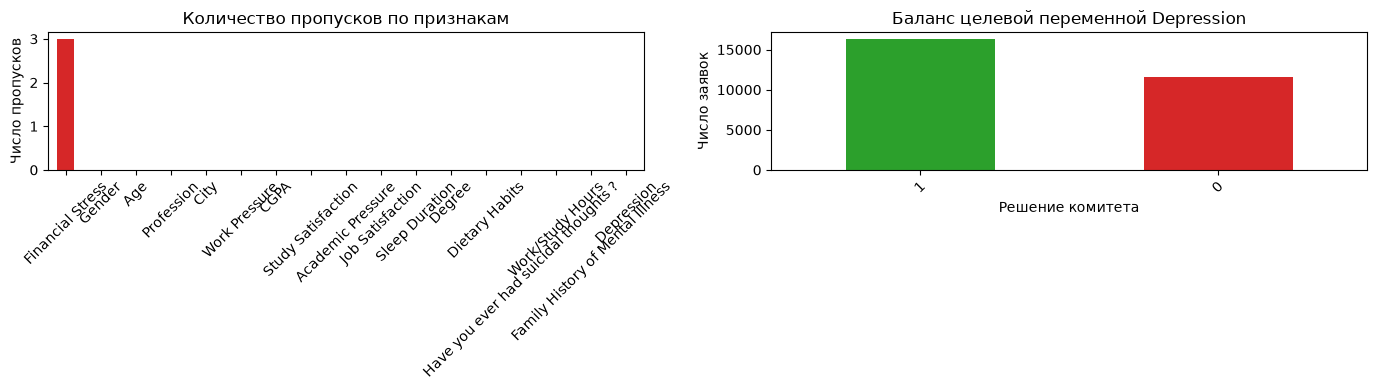

Depression
1    0.585
0    0.415
Name: proportion, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.isna().sum().sort_values(ascending=False).plot.bar(ax=axes[0], color="tab:red")
axes[0].set_title("Количество пропусков по признакам")
axes[0].set_ylabel("Число пропусков")
df["Depression"].value_counts().plot.bar(ax=axes[1], color=["tab:green", "tab:red"])
axes[1].set_title("Баланс целевой переменной Depression")
axes[1].set_xlabel("Решение комитета")
axes[1].set_ylabel("Число заявок")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
print(df["Depression"].value_counts(normalize=True).round(3))

3.1398666571080365 3.0


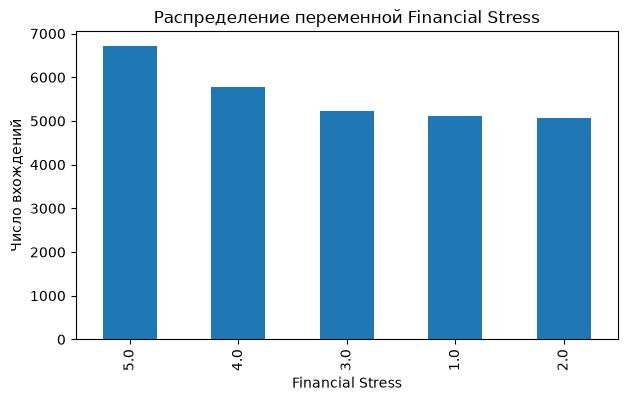

In [7]:
fig, axes = plt.subplots(1, 1, figsize=(7, 4))
df["Financial Stress"].value_counts().plot.bar(ax=axes)
axes.set_title("Распределение переменной Financial Stress")
axes.set_ylabel("Число вхождений")

print(df["Financial Stress"].mean(), df["Financial Stress"].median())

In [8]:
df[df["Financial Stress"].isna()]

,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
id,,,,,,,,,,,,,,,,,
22377,Female,32.0,Varanasi,Student,3.0,0.0,5.64,1.0,0.0,5-6 hours,Healthy,BCA,No,12.0,NaN,No,1
68910,Male,29.0,Hyderabad,Student,2.0,0.0,8.94,3.0,0.0,Less than 5 hours,Unhealthy,B.Ed,No,12.0,NaN,Yes,0
97610,Female,20.0,Kolkata,Student,1.0,0.0,6.83,1.0,0.0,5-6 hours,Healthy,MBBS,No,9.0,NaN,Yes,0


## Задание 2. Базовое обучение двух моделей [1 балл]

Выбери **две модели** из списка:

- `LogisticRegression`;
- `DecisionTreeClassifier`;
- `RandomForestClassifier`;
- `KNeighborsClassifier`.

На этом этапе **не подбирай гиперпараметры**: цель — получить базовый результат, с которым потом можно будет сравнить доработанные модели.

1. Разбей данные на train и test — **[0,2 балла]**.
2. Создай и обучи две выбранные модели — **[0,3 балла]**.
3. Посчитай `Accuracy` на train и test для каждой модели — **[0,3 балла]**.
4. Сравни train и test. Есть ли у какой-то модели признаки переобучения? Объясни ответ текстом — **[0,2 балла]**.




**Примечание.** Accuracy — это доля объектов, для которых модель правильно предсказала класс.

Формально Accuracy можно записать как

$\mathrm{Accuracy} = \frac{\text{число правильных предсказаний}}{\text{общее число объектов}}$.

Значение Accuracy всегда лежит в диапазоне

$0 \leq \mathrm{Accuracy} \leq 1$.

Чем ближе значение к $1$, тем больше правильных ответов дала модель. Например, $\mathrm{Accuracy}=0,8$ означает, что модель правильно классифицировала $80\%$ объектов.

Рассмотрим пример. Пусть истинные классы объектов равны

$y_{\text{train}} = [1, 1, 0, 0]$,

а предсказания модели:

$y_{\text{predicted}} = [0, 0, 1, 1]$.

В данном случае модель ошиблась на всех четырёх объектах, поэтому число правильных предсказаний равно $0$.

Следовательно,

$\mathrm{Accuracy} = \frac{0}{4} = 0$.

То есть

$\mathrm{accuracy\_score}(y_{\text{train}}, y_{\text{predicted}}) = 0$.

Таким образом, Accuracy, равная $0$, означает, что модель не угадала правильный класс ни для одного объекта.

In [9]:
# Напиши код здесь

#### Напиши ответ на вопрос здесь

## Задание 3. Доработка моделей: подбор гиперпараметров [2,5 балла]

Теперь **доработай те же две модели**, которые выбраны в задании 2.

1. Задай сетки гиперпараметров для обеих моделей — **[0,5 балла]**.
2. Запусти `GridSearchCV` (или `RandomizedSearchCV`) с 5-fold кросс-валидацией **только на train** — **[1 балл]**.
3. Для каждой модели выведи лучшие гиперпараметры, среднее качество по фолдам и стандартное отклонение — **[0,5 балла]**.
4. После выбора гиперпараметров **один раз** оцени лучшую версию каждой модели на test и сравни с базовым результатом из задания 2 — **[0,5 балла]**.

Подсказки по параметрам:

- `LogisticRegression`: `C`, `solver`;
- `DecisionTreeClassifier`: `max_depth`, `min_samples_leaf`, `min_samples_split`, `max_features`;
- `RandomForestClassifier`: `n_estimators`, `max_depth`, `max_features`, `min_samples_leaf`;
- `KNeighborsClassifier`: `n_neighbors`, `weights`, `p`.

> Test не участвует в подборе гиперпараметров. `GridSearchCV` сам делит train на фолды.


In [10]:
# Напиши код здесь

## Задание 4 [3 балла]

Построй интервальную оценку качества для **двух доработанных моделей** с помощью бутстрепа.

1. Реализуй бутстреп-оценку `Accuracy` (например, 50–300 повторов) — **[1 балл]**.
2. Для каждой из двух моделей построй 95-процентный доверительный интервал — **[1 балл]**.
3. Построй гистограммы распределений бутстреп-оценок — **[1 балл]**.

Вспомним используемую здесь схему бутстрепа:

- берём bootstrap sample с повторениями и используем его как обучающую выборку;
- объекты, которые не попали в bootstrap sample, образуют out-of-bag-выборку;
- оцениваем качество на out-of-bag-объектах;
- повторяем процесс много раз и получаем распределение значений метрики.


In [11]:
# Напиши код здесь

## Задание 6 [2 балла]

Сравни две модели по полученным 95-процентным доверительным интервалам.

1. Сравни **ширину** интервалов. Что она говорит об оценке качества? — **[0,6 балла]**.
2. Проверь, **пересекаются ли** доверительные интервалы двух моделей — **[0,6 балла]**.
3. Можно ли по результатам этого бутстреп-эксперимента уверенно утверждать, что одна модель лучше другой? Объясни вывод — **[0,8 балла]**.

> В этом задании ориентируйся именно на взаимное положение интервалов. Узкий интервал сам по себе не означает, что модель лучше.


Напиши свои выводы здесь.


In [12]:
# Проверим пересечение интервалов программно

names = list(boot_results.keys())
name_1, name_2 = names[0], names[1]

left_1, right_1 = boot_results[name_1]["left"], boot_results[name_1]["right"]
left_2, right_2 = boot_results[name_2]["left"], boot_results[name_2]["right"]

intervals_overlap = max(left_1, left_2) <= min(right_1, right_2)

print(f"{name_1}: [{left_1:.4f}, {right_1:.4f}]")
print(f"{name_2}: [{left_2:.4f}, {right_2:.4f}]")
print("Интервалы пересекаются:", intervals_overlap)


NameError: name 'boot_results' is not defined